<a href="https://colab.research.google.com/github/nikos0406/UNI-NN-and-DL/blob/main/NN_HW1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [49]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler

from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


# **Part 0 First exploration**

**0.1 Load both files**

In [50]:
df_customers = pd.read_csv("/content/drive/MyDrive/NN_HW1/data/customers.csv")

df_usage = pd.read_csv("/content/drive/MyDrive/NN_HW1/data/monthly_usage.csv")

**0.2  Type and number of missing values**

In [51]:
print("CUSTOMERS")
print(df_customers.dtypes)
print(df_customers.isnull().sum(), '\n')

print("MONTHLY USAGE")
print(df_usage.dtypes)
print(df_usage.isnull().sum())

CUSTOMERS
customer_id            object
gender                 object
date_of_birth          object
city                   object
contract_type          object
tenure_months         float64
monthly_charge_usd    float64
num_complaints          int64
churn                  object
dtype: object
customer_id            0
gender                24
date_of_birth         43
city                  25
contract_type          0
tenure_months         48
monthly_charge_usd    36
num_complaints         0
churn                  0
dtype: int64 

MONTHLY USAGE
cust_no              int64
month               object
minutes_day        float64
minutes_evening    float64
minutes_night      float64
total_minutes      float64
sms_count            int64
data_volume        float64
data_unit           object
dtype: object
cust_no              0
month                0
minutes_day        134
minutes_evening      0
minutes_night        0
total_minutes        0
sms_count            0
data_volume          0
data_unit  

**0.3  Distinc values**

In [52]:
columns = ["gender", "city", "contract_type", "churn"]

for c in columns:
  print(c, ':', df_customers[c].unique())

gender : ['M' 'F' ' M' 'f' 'm' nan 'Male' 'F ' 'Female' 'male' 'female']
city : ['Kinshasa' 'Addis Ababa' nan 'Gonder' 'Hawassa' 'Goma' 'Gondar'
 'Kisangani' 'Bahir Dar' 'ADDIS ABABA' 'kinshasa' 'Kinshasa ' 'goma'
 'Lubumbashi' 'Awassa' 'KINSHASA' 'addis ababa' 'Bahirdar' 'bahir dar'
 'lubumbashi' 'kisangani' 'Lubumbachi' 'Addis-Ababa']
contract_type : ['Postpaid' 'Prepaid' 'Post-paid' 'prepaid' 'Pre-paid' 'PREPAID'
 'POSTPAID' 'postpaid']
churn : ['Yes' 'No']


What i noticed:
- Many different descriptions are used for the same category
- 'nan' in gender category

**0.4  Min max numeric columns**

In [53]:
numeric_columns_customers = ["tenure_months", "monthly_charge_usd", "num_complaints"]

print("CUSTOMERS:", '\n')

for nc in numeric_columns_customers:
  print("MAX:", nc, df_customers[nc].max())

for nc in numeric_columns_customers:
  print("MIN:", nc, df_customers[nc].min())

print('\n')


numeric_columns_monthly = ["cust_no", "minutes_day", "minutes_evening", "minutes_night",
                           "total_minutes", "sms_count", "data_volume"]

print("MONTHLY USAGE:", '\n')

for nc in numeric_columns_monthly:
  print("MAX:", nc, df_usage[nc].max())

for nc in numeric_columns_monthly:
  print("MIN:", nc, df_usage[nc].min())

CUSTOMERS: 

MAX: tenure_months 96.0
MAX: monthly_charge_usd 9999.0
MAX: num_complaints 5
MIN: tenure_months -12.0
MIN: monthly_charge_usd 8.43
MIN: num_complaints 0


MONTHLY USAGE: 

MAX: cust_no 1383
MAX: minutes_day 1860.3
MAX: minutes_evening 1241.4
MAX: minutes_night 376.9
MAX: total_minutes 3473.7
MAX: sms_count 315
MAX: data_volume 9999999.0
MIN: cust_no 1
MIN: minutes_day 13.1
MIN: minutes_evening 0.0
MIN: minutes_night 0.0
MIN: total_minutes 13.1
MIN: sms_count 5
MIN: data_volume -1.0


Impossible numbers I found:
- CUSTOMERS
  - tenure_months min = -12
  - monthly_charge_usd max = 9999

- MONTHLY USAGE
  - data_volume min = -1, max = 999999999999

**0.5  Monthly charge histogram & data  volume box plot**

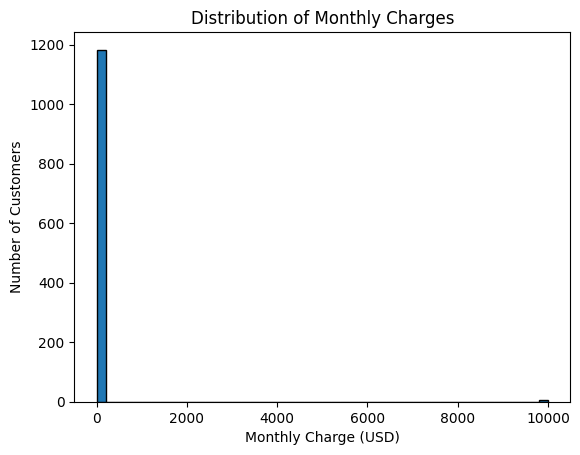

In [54]:
charges = df_customers["monthly_charge_usd"]

plt.hist(charges, bins=50, edgecolor="black")

plt.xlabel("Monthly Charge (USD)")
plt.ylabel("Number of Customers")
plt.title("Distribution of Monthly Charges")

plt.show()

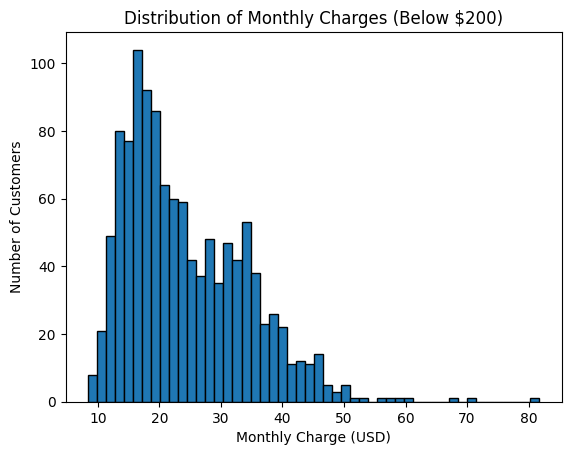

In [55]:

charges = df_customers["monthly_charge_usd"]

plt.hist(charges[charges < 200], bins=50, edgecolor="black")

plt.xlabel("Monthly Charge (USD)")
plt.ylabel("Number of Customers")
plt.title("Distribution of Monthly Charges (Below $200)")

plt.show()

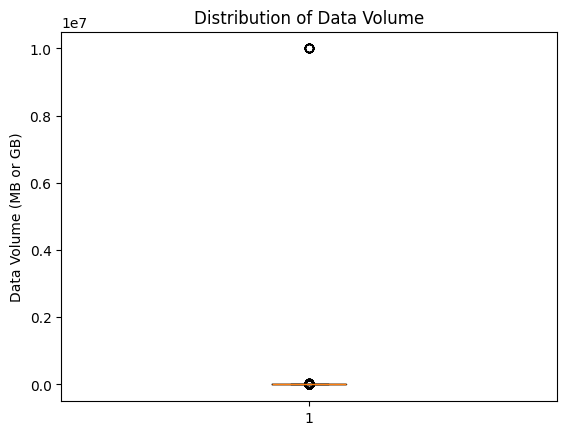

In [56]:
usage = df_usage["data_volume"]

plt.boxplot(usage)

plt.ylabel("Data Volume (MB or GB)")
plt.title("Distribution of Data Volume")

plt.show()

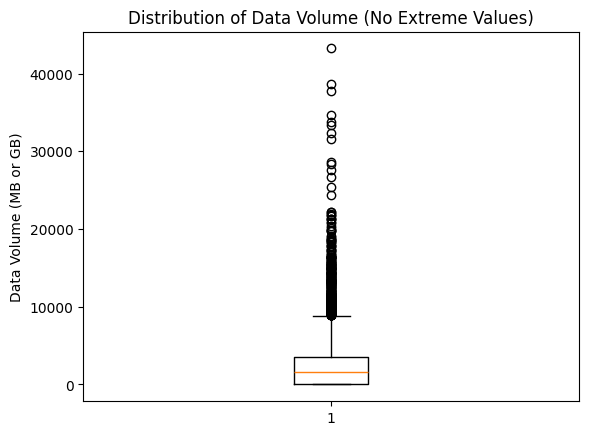

In [57]:
usage = df_usage["data_volume"]

plt.boxplot(usage[usage < 500000])

plt.ylabel("Data Volume (MB or GB)")
plt.title("Distribution of Data Volume (No Extreme Values)")

plt.show()

**0.6  Issues**
- Different description format for same categories
- Missing datapoints
- Impossible data points

# **Part 1 Data cleaning**

**1.1  Duplicates**

In [58]:
print("Duplicates CUSTOMERS:", df_customers.duplicated().sum())
print("Duplicates MONTHLY USAGE:", df_usage.duplicated().sum())

customers = df_customers.drop_duplicates().copy() # Copy creates an independent DF, otherwise we get Memory Safety warnings later.
usage = df_usage.drop_duplicates().copy()

print("\nDuplicates CUSTOMERS:", customers.duplicated().sum())
print("Duplicates MONTHLY USAGE:", usage.duplicated().sum())

Duplicates CUSTOMERS: 25
Duplicates MONTHLY USAGE: 30

Duplicates CUSTOMERS: 0
Duplicates MONTHLY USAGE: 0


In [59]:
print("Duplicated customer_id:", customers["customer_id"].duplicated().sum())

print("Duplicated cust_no, month pairs:", usage.duplicated(subset=["cust_no", "month"]).sum())

Duplicated customer_id: 0
Duplicated cust_no, month pairs: 0


**1.2  Inconsistent data**

In [60]:
print("Gender:", customers["gender"].unique())
print("\nCity:", customers["city"].unique())
print("\nContract:", customers["contract_type"].unique())

Gender: ['M' 'F' ' M' 'f' 'm' nan 'Male' 'F ' 'Female' 'male' 'female']

City: ['Kinshasa' 'Addis Ababa' nan 'Gonder' 'Hawassa' 'Goma' 'Gondar'
 'Kisangani' 'Bahir Dar' 'ADDIS ABABA' 'kinshasa' 'Kinshasa ' 'goma'
 'Lubumbashi' 'Awassa' 'KINSHASA' 'addis ababa' 'Bahirdar' 'bahir dar'
 'lubumbashi' 'kisangani' 'Lubumbachi' 'Addis-Ababa']

Contract: ['Postpaid' 'Prepaid' 'Post-paid' 'prepaid' 'Pre-paid' 'PREPAID'
 'POSTPAID' 'postpaid']


In [61]:
customers["gender"] = (
    customers["gender"]
    .str.strip()
    .str.lower()
    .replace({
        "male": "m",
        "female": "f",
    })
    .str.title()
)

print("Gender:", customers["gender"].unique())

Gender: ['M' 'F' nan]


In [62]:
customers["city"] = (
    customers["city"]
    .str.strip()
    .str.lower()
    .replace({
      "addis-ababa": "addis ababa",
      "gonder": "gondar",
      "lubumbachi": "lubumbashi",
      "awassa": "hawassa",
      "bahirdar": "bahir dar",
    })
    .str.title()
)

print("City:", customers["city"].unique())

City: ['Kinshasa' 'Addis Ababa' nan 'Gondar' 'Hawassa' 'Goma' 'Kisangani'
 'Bahir Dar' 'Lubumbashi']


In [63]:
customers["contract_type"] = (
    customers["contract_type"]
    .str.strip()
    .str.lower()
    .replace({
      "pre-paid": "prepaid",
      "post-paid": "postpaid",
    })
    .str.title()
)

print("Contract Type:", customers["contract_type"].unique())

Contract Type: ['Postpaid' 'Prepaid']


**1.3  Invalid values**

In [64]:
invalid_tenure = customers["tenure_months"] < 0

print("Invalid tenure:", invalid_tenure.sum())

customers.loc[invalid_tenure, "tenure_months"] = np.nan

Invalid tenure: 8


In [65]:
invalid_charge = customers["monthly_charge_usd"] == 9999

print("Invalid charges:", invalid_charge.sum())

customers.loc[invalid_charge, "monthly_charge_usd"] = np.nan

Invalid charges: 6


In [66]:
customers["date_of_birth"] = pd.to_datetime(
    customers["date_of_birth"],
    errors="coerce"
)

today = pd.Timestamp.today().normalize()

invalid_age = (
    (customers["date_of_birth"] > today - pd.DateOffset(years=16)) |
    (customers["date_of_birth"] < today - pd.DateOffset(years=100))
)

print("Invalid ages:", invalid_age.sum())

customers.loc[invalid_age, "date_of_birth"] = pd.NaT

Invalid ages: 5


In [67]:
invalid_volume = (
    (usage["data_volume"] < 0) |
    (usage["data_volume"] > 1_000_000)
)

print("Invalid data volumes:", invalid_volume.sum())

usage.loc[invalid_volume, "data_volume"] = np.nan

Invalid data volumes: 32


In [68]:
print("# of replaced values for each rule:\n")

results = pd.Series({
    "Negative tenure": invalid_tenure.sum(),
    "Charge = 9999": invalid_charge.sum(),
    "Invalid age": invalid_age.sum(),
    "Invalid data volume": invalid_volume.sum()
})

print(results)

# of replaced values for each rule:

Negative tenure         8
Charge = 9999           6
Invalid age             5
Invalid data volume    32
dtype: int64


**1.4  Missing values**

In [69]:
print("Tenure skewness:", customers["tenure_months"].skew())
print("Charge skewness:", customers["monthly_charge_usd"].skew())

Tenure skewness: 0.16597146922974848
Charge skewness: 0.9720854083399145


In [70]:
for col in ["tenure_months", "monthly_charge_usd"]:
    skew = customers[col].skew()

    if abs(skew) > 0.5:
        value = customers[col].median()
        method = "median"
    else:
        value = customers[col].mean()
        method = "mean"

    print(col, "using", method, "=", value)
    customers[col] = customers[col].fillna(value)

tenure_months using mean = 40.26311188811189
monthly_charge_usd using median = 21.845


In [71]:
print(customers["gender"].mode())
print(customers["city"].mode())

0    M
Name: gender, dtype: object
0    Kinshasa
Name: city, dtype: object


In [72]:
customers["gender"] = customers["gender"].fillna(
    customers["gender"].mode()[0]
)

customers["city"] = customers["city"].fillna(
    customers["city"].mode()[0]
)

print("Gender:", customers["gender"].unique())
print("City:", customers["city"].unique())

Gender: ['M' 'F']
City: ['Kinshasa' 'Addis Ababa' 'Gondar' 'Hawassa' 'Goma' 'Kisangani'
 'Bahir Dar' 'Lubumbashi']


In [73]:
customers["date_of_birth"] = pd.to_datetime(
    customers["date_of_birth"]
)

median_date = customers["date_of_birth"].median()

print("Median date:", median_date)

customers["date_of_birth"] = customers["date_of_birth"].fillna(median_date)

Median date: 1989-03-13 00:00:00


In [74]:
missing = usage["minutes_day"].isna()

rebuilt = (
    usage["total_minutes"]
    - usage["minutes_evening"]
    - usage["minutes_night"]
)

valid = missing & rebuilt.notna() & (rebuilt >= 0)

print("Values rebuilt:", valid.sum())

usage["minutes_day"] = usage["minutes_day"].fillna(
    rebuilt.where(valid)
)

Values rebuilt: 133


**Why not just delete the values?**
- It is not worth it deleting a whole customer, just because one value is missing.
- We would lose too much valuable data

**1.5  Noisy data**

In [75]:
customers["charge_bin"] = pd.qcut(
    customers["monthly_charge_usd"],
    q=10,
    labels=False
)

customers["charge_smoothed"] = (
    customers.groupby("charge_bin")["monthly_charge_usd"]
    .transform("mean")
)

display(
    customers[["charge_bin", "charge_smoothed"]]
    .drop_duplicates()
    .sort_values("charge_bin")
)

,charge_bin,charge_smoothed
28,0,12.100083
20,1,14.909417
5,2,16.829167
12,3,18.728667
7,4,21.086170
24,5,23.105455
1,6,26.577107
2,7,30.888151
0,8,34.919500
3,9,43.650000


**1.6  Outliers**

In [76]:
usage["data_volume_mb"] = usage["data_volume"].copy()
usage.loc[usage["data_unit"] == "GB", "data_volume_mb"] *= 1024

q1 = usage["data_volume_mb"].quantile(0.25)
q3 = usage["data_volume_mb"].quantile(0.75)

iqr = q3 - q1
fence = q3 + 1.5 * iqr

outliers = usage["data_volume_mb"] > fence

print("Q1:", q1)
print("Q3:", q3)
print("IQR:", iqr)
print("Upper fence:", fence)
print("Number of outliers:", outliers.sum())

display(usage.loc[outliers].sort_values("data_volume_mb", ascending=False))

Q1: 1565.0255000000002
Q3: 4674.4485
IQR: 3109.4230000000002
Upper fence: 9338.583
Number of outliers: 407


,cust_no,month,minutes_day,minutes_evening,minutes_night,total_minutes,sms_count,data_volume,data_unit,data_volume_mb
1899,1168,2026-02,270.6,172.5,60.8,503.9,71,52.282,GB,53536.768
1346,1168,2026-03,179.2,98.9,29.5,307.6,59,43225.642,MB,43225.642
752,739,2026-01,225.3,143.2,49.4,417.9,75,40.672,GB,41648.128
6514,1139,2026-04,128.9,96.7,32.1,257.7,31,38608.723,MB,38608.723
5868,1168,2026-04,320.8,198.9,68.4,588.1,92,37721.604,MB,37721.604
...,...,...,...,...,...,...,...,...,...,...
6257,761,2026-02,556.8,389.0,105.6,1051.4,100,9.165,GB,9384.960
2958,484,2026-04,140.2,112.9,16.3,269.4,48,9372.145,MB,9372.145
1821,1080,2026-01,132.0,72.7,26.6,231.3,27,9.148,GB,9367.552
5520,763,2026-06,311.8,215.2,69.6,596.6,38,9352.033,MB,9352.033


# **Part 2 Data integration**

**2.1 Common customer ID**

In [77]:
customers["cust_no"] = customers["customer_id"].str.split("-").str[-1].astype(int) # CUST-00052 gets split, picks last part (number) and turns it into int dt

**2.2 Aggregation**

In [78]:
# Multiple rows with name cust_no in usage, so we create a new table to summarize
usage_agg = usage.groupby("cust_no").agg(
    months_count=("month", "nunique"),
    avg_minutes_day=("minutes_day", "mean"),
    avg_minutes_evening=("minutes_evening", "mean"),
    avg_minutes_night=("minutes_night", "mean"),
    avg_total_minutes=("total_minutes", "mean"),
    avg_sms_count=("sms_count", "mean"),
    avg_data_volume_mb=("data_volume_mb", "mean")
).reset_index()

**2.3 Merge with left joint**

In [79]:
merged = customers.merge(usage_agg, on="cust_no", how="left")

**2.4 Check missing usage records**

In [80]:
no_usage = merged["months_count"].isna().sum()
print("Customers without usage:", no_usage)

unknown = set(usage["cust_no"]) - set(customers["cust_no"])
print("Usage IDs not in CRM:", len(unknown))

merged["months_count"] = merged["months_count"].fillna(0)

Customers without usage: 40
Usage IDs not in CRM: 15


**2.5 Check missing usage records**

In [81]:
print("Total customers:", len(customers))
print("Merged rows:", len(merged))
print("Unique customers:", merged["cust_no"].nunique())

assert len(merged) == len(customers)
assert merged["cust_no"].is_unique

print("Final table has exactly one row per customer!")

Total customers: 1200
Merged rows: 1200
Unique customers: 1200
Final table has exactly one row per customer!


# **Part 3 Data transformation**

**3.1 Attribute Construction**

In [82]:
birth = pd.to_datetime(merged["date_of_birth"])

merged["age"] = 2026 - birth.dt.year

# Subtract 1 if the birthday hasn't happened yet
not_yet = (birth.dt.month > 6) | (
    (birth.dt.month == 6) & (birth.dt.day > 30)
)

merged["age"] = merged["age"] - not_yet.astype(int)

merged["is_senior"] = (merged["age"] >= 60).astype(int)

print("Senior customers:", merged["is_senior"].sum())

Senior customers: 64


**3.2 Attribute Construction**

In [83]:
countries = {
    "Kinshasa": "DR Congo",
    "Lubumbashi": "DR Congo",
    "Goma": "DR Congo",
    "Kisangani": "DR Congo",
    "Addis Ababa": "Ethiopia",
    "Gondar": "Ethiopia",
    "Bahir Dar": "Ethiopia",
    "Hawassa": "Ethiopia"
}

merged["country"] = merged["city"].map(countries)

print(merged["country"].value_counts(dropna=False))

merged["churn_numeric"] = merged["churn"].map({"Yes": 1, "No": 0})

churn_rate = merged.groupby("country")["churn_numeric"].mean() * 100

print(churn_rate)

country
DR Congo    662
Ethiopia    538
Name: count, dtype: int64
country
DR Congo    12.990937
Ethiopia    15.241636
Name: churn_numeric, dtype: float64


**3.3 Normalization**

In [84]:
columns = [
    "tenure_months",
    "monthly_charge_usd",
    "num_complaints",
    "age",
    "avg_minutes_day",
    "avg_minutes_evening",
    "avg_minutes_night",
    "avg_total_minutes",
    "avg_sms_count",
    "avg_data_volume_mb"
]

In [85]:
minmax = (
    (merged[columns] - merged[columns].min())
    / (merged[columns].max() - merged[columns].min())
)

print("Minimum:")
print(minmax.min())

print("\nMaximum:")
print(minmax.max())

Minimum:
tenure_months          0.0
monthly_charge_usd     0.0
num_complaints         0.0
age                    0.0
avg_minutes_day        0.0
avg_minutes_evening    0.0
avg_minutes_night      0.0
avg_total_minutes      0.0
avg_sms_count          0.0
avg_data_volume_mb     0.0
dtype: float64

Maximum:
tenure_months          1.0
monthly_charge_usd     1.0
num_complaints         1.0
age                    1.0
avg_minutes_day        1.0
avg_minutes_evening    1.0
avg_minutes_night      1.0
avg_total_minutes      1.0
avg_sms_count          1.0
avg_data_volume_mb     1.0
dtype: float64


In [86]:
zscore = (
    (merged[columns] - merged[columns].mean())
    / merged[columns].std()
)

print("Mean:")
print(zscore.mean().round(3))

print("\nStandard deviation:")
print(zscore.std().round(3))

Mean:
tenure_months          0.0
monthly_charge_usd     0.0
num_complaints        -0.0
age                   -0.0
avg_minutes_day       -0.0
avg_minutes_evening   -0.0
avg_minutes_night     -0.0
avg_total_minutes     -0.0
avg_sms_count          0.0
avg_data_volume_mb     0.0
dtype: float64

Standard deviation:
tenure_months          1.0
monthly_charge_usd     1.0
num_complaints         1.0
age                    1.0
avg_minutes_day        1.0
avg_minutes_evening    1.0
avg_minutes_night      1.0
avg_total_minutes      1.0
avg_sms_count          1.0
avg_data_volume_mb     1.0
dtype: float64


Distance-based models such as k-NN are sensitive to differences in feature scales, because variables with larger numerical ranges can dominate calculations. Normalization puts features on comparable scales.

**3.4 Discretization**

In [87]:
merged["age_group"] = pd.cut(
    merged["age"],
    bins=[-1, 17, 43, 60, float("inf")],
    labels=["<18", "18-43", "44-60", ">60"]
)

In [88]:
merged["tenure_group"] = pd.cut(
    merged["tenure_months"],
    bins=[-1, 12, 24, 48, float("inf")],
    labels=["0-12", "13-24", "25-48", ">48"]
)

In [89]:
churn_by_tenure = (
    merged.groupby("tenure_group", observed=True)["churn_numeric"]
    .mean() * 100
)

print(churn_by_tenure)

tenure_group
0-12     32.402235
13-24    19.774011
25-48    13.164557
>48       5.122494
Name: churn_numeric, dtype: float64


New customers have the highest churn rate.

**3.5 Encoding (Bonus)**

In [90]:
# E.g. creates columns gender_M & gender_F and assigns numeric values
encoded = pd.get_dummies(
    merged,
    columns=["gender", "contract_type", "country"],
    dtype=int
)

# No new column, simply assigns 0 & 1 to churn
encoded["churn"] = encoded["churn"].map({"Yes": 1, "No": 0})

display(encoded.head())

,customer_id,date_of_birth,city,tenure_months,monthly_charge_usd,num_complaints,churn,charge_bin,charge_smoothed,cust_no,...,is_senior,churn_numeric,age_group,tenure_group,gender_F,gender_M,contract_type_Postpaid,contract_type_Prepaid,country_DR Congo,country_Ethiopia
0,CUST-00052,2006-03-21,Kinshasa,11.0,37.16,1,1,8,34.919500,52,...,0,1,18-43,0-12,0,1,1,0,1,0
1,CUST-00523,1999-06-22,Kinshasa,9.0,24.93,0,0,6,26.577107,523,...,0,0,18-43,0-12,1,0,0,1,1,0
2,CUST-00180,1999-08-14,Addis Ababa,67.0,30.68,1,0,7,30.888151,180,...,0,0,18-43,>48,0,1,1,0,0,1
3,CUST-01174,1997-02-10,Addis Ababa,59.0,44.44,1,0,9,43.650000,1174,...,0,0,18-43,>48,0,1,0,1,0,1
4,CUST-00938,1982-10-09,Kinshasa,18.0,32.15,2,0,7,30.888151,938,...,0,0,18-43,13-24,1,0,1,0,1,0


# **Part 4 Data reduction**

**4.1 Redundant feature**

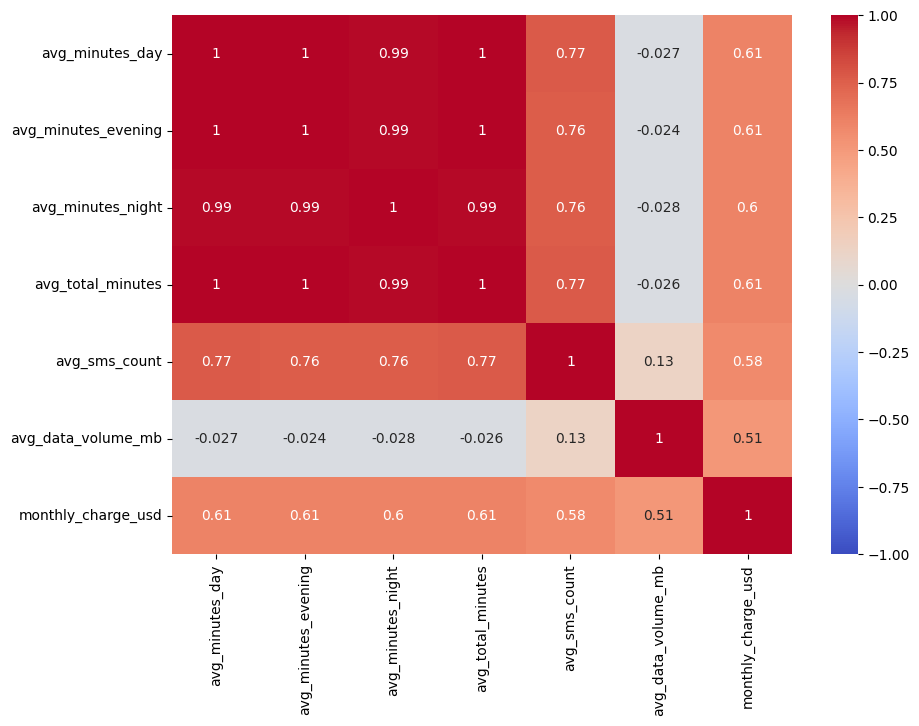

In [91]:
columns = [
    "avg_minutes_day",
    "avg_minutes_evening",
    "avg_minutes_night",
    "avg_total_minutes",
    "avg_sms_count",
    "avg_data_volume_mb",
    "monthly_charge_usd"
]

corr = merged[columns].corr()

plt.figure(figsize=(10, 7))
sns.heatmap(corr, annot=True, cmap="coolwarm", vmin=-1, vmax=1)
plt.show()

In [92]:
difference = (
    merged["avg_total_minutes"]
    - merged["avg_minutes_day"]
    - merged["avg_minutes_evening"]
    - merged["avg_minutes_night"]
)

print(difference.abs().max())

3.979039320256561e-13


The maximum difference is approximately zero (3.98e-13). Therefore, avg_total_minutes is redundant because it can be reconstructed from the other three minute columns.

**4.2 PCA (dimension reduction)**

In [97]:
columns = [
    "avg_minutes_day",
    "avg_minutes_evening",
    "avg_minutes_night",
    "avg_total_minutes",
    "avg_sms_count",
    "avg_data_volume_mb"
]

X = merged[columns].dropna()

X_scaled = StandardScaler().fit_transform(X)

pca = PCA()
pca.fit(X_scaled)

components = pd.DataFrame(
    pca.components_[:3],
    index=["PC1", "PC2", "PC3"],
    columns=X.columns
)

components["Variance explained (%)"] = pca.explained_variance_ratio_[:3] * 100

display(components.round(3))

variance = pca.explained_variance_ratio_
cumulative = np.cumsum(variance)

results = pd.DataFrame({
    "Component": range(1, 7),
    "Explained variance (%)": (variance * 100).round(2),
    "Cumulative variance (%)": (cumulative * 100).round(2)
})

display(results)

,avg_minutes_day,avg_minutes_evening,avg_minutes_night,avg_total_minutes,avg_sms_count,avg_data_volume_mb,Variance explained (%)
PC1,0.461,0.460,0.459,0.461,0.389,0.00,77.171
PC2,-0.040,-0.038,-0.040,-0.039,0.184,0.98,17.138
PC3,-0.186,-0.198,-0.188,-0.191,0.902,-0.20,5.398


,Component,Explained variance (%),Cumulative variance (%)
0,1,77.17,77.17
1,2,17.14,94.31
2,3,5.40,99.71
3,4,0.25,99.95
4,5,0.05,100.00
5,6,0.00,100.00


PCA shows that the first two components explain 94.31% of the total variance, so 2 components are sufficient to retain at least 90%. To retain at least 95%, 3 components are needed, explaining 99.71% of the variance. The sixth component explains almost no additional variance due to redundancy in the original features.

**4.3 Size**

In [94]:
raw_size = (
    df_customers.memory_usage(deep=True).sum()
    + df_usage.memory_usage(deep=True).sum()
)

final_size = merged.memory_usage(deep=True).sum()

reduction = (1 - final_size / raw_size) * 100

print("Original size:", round(raw_size / 1024, 2), "KB")
print("Final size:", round(final_size / 1024, 2), "KB")
print("Reduction:", round(reduction, 2), "%")

Original size: 1490.31 KB
Final size: 550.54 KB
Reduction: 63.06 %


**4.4 Think ahead**

In [95]:
X_train, X_test = train_test_split(
    merged[["age", "tenure_months", "monthly_charge_usd"]],
    test_size=0.2,
    random_state=42
)

scaler = MinMaxScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training data:", X_train_scaled.shape)
print("Test data:", X_test_scaled.shape)

Training data: (960, 3)
Test data: (240, 3)


# **Exporting cleaned table**

In [96]:
from pathlib import Path

customers_clean = merged.copy()

usage_columns = [
    "avg_minutes_day",
    "avg_minutes_evening",
    "avg_minutes_night",
    "avg_total_minutes",
    "avg_sms_count",
    "avg_data_volume_mb",
]

has_usage = customers_clean["months_count"].gt(0)

usage_medians = customers_clean.loc[has_usage, usage_columns].median()

customers_clean.loc[~has_usage, usage_columns] = 0.0
customers_clean[usage_columns] = customers_clean[usage_columns].fillna(usage_medians)
customers_clean["months_count"] = customers_clean["months_count"].astype(int)

assert len(customers_clean) == len(customers), "Customer row count changed."
assert customers_clean["customer_id"].is_unique, "Duplicate customer IDs."
assert not customers_clean.isna().any().any(), "Missing values remain."

output_path = Path("/content/drive/MyDrive/NN_HW1/data/customers_clean.csv")
customers_clean.to_csv(output_path, index=False)

print(f"Saved {len(customers_clean):,} customers to {output_path}")

Saved 1,200 customers to /content/drive/MyDrive/NN_HW1/data/customers_clean.csv
